In [2]:
import os
import glob
import pickle
import numpy as np
import pandas as pd
from scipy.stats import gaussian_kde

import matplotlib.pyplot as plt
import matplotlib as mpl
%matplotlib inline

mpl.rcParams['font.size']    = 8.0
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['font.family']  = 'Arial'



In [ ]:
bin_size      = 0.1
stim_duration = 10.0
kde_bw        = 0.06
n_kde_full    = 1000

pred_path  = './dataFolder/5_1DCompModel_Train/Prediction/'
orig_path  = '../dataFolder/2_Raster_PSTH/'                          # 30-rep KDEs from original pipeline
train_path = '../dataFolder/4_RawData_Index_Timestamp/Train/'        # not used directly; just for reference

out_data = './dataFolder/Summary/'
out_fig  = './dataFolder/Figures_Summary/'
os.makedirs(out_data, exist_ok=True)
os.makedirs(out_fig,  exist_ok=True)

rng = np.random.default_rng(0)   # reproducible jitter

In [3]:
moth_unit = [('m23', 'unit_1'),
             ('m29', 'unit_1'),
             ('m30', 'unit_1'),
             ('m31', 'unit_1'),
             ('m31', 'unit_2'),
             ('m31', 'unit_3'),
             ('m11', 'unit_2'),
             ('m11', 'unit_3')]

records = []

for name, unit_name in moth_unit:
    #make sure to load for all kde points not matching psth-kde
    pred_file = pred_path + name + '_' + unit_name + '_Prediction.pickle'
    with open(pred_file, 'rb') as f:
        saved = pickle.load(f)
    density_test = saved[7]
    density_pred = saved[8]
    
    # (load 30-rep original KDE (from original pipeline nb 2?)
    orig_csv = orig_path + name + '_' + unit_name + '_kde_full.csv'
    df_orig = pd.read_csv(orig_csv)
    density_orig = df_orig['kde'].values
    
    rmse_orig_test = float(np.sqrt(np.mean((density_orig - density_test) ** 2)))
    rmse_test_pred = float(np.sqrt(np.mean((density_test - density_pred) ** 2)))
    
    records.append({
        'moth':           name,
        'unit':           unit_name,
        'rmse_orig_test': rmse_orig_test,
        'rmse_test_pred': rmse_test_pred,
    })
    print(f'{name} {unit_name}: orig-test={rmse_orig_test:.4f}, test-pred={rmse_test_pred:.4f}')

df_rmse = pd.DataFrame(records).sort_values(['moth','unit']).reset_index(drop=True)
df_rmse.to_csv(out_data + 'rmse_values.csv', index=False)
df_rmse

m23 unit_1: orig-test=0.0063, test-pred=0.0165
m29 unit_1: orig-test=0.0157, test-pred=0.0262
m30 unit_1: orig-test=0.0039, test-pred=0.0170
m31 unit_1: orig-test=0.0071, test-pred=0.0191
m31 unit_2: orig-test=0.0115, test-pred=0.0260
m31 unit_3: orig-test=0.0229, test-pred=0.0572
m11 unit_2: orig-test=0.0203, test-pred=0.0733
m11 unit_3: orig-test=0.0144, test-pred=0.1151


,moth,unit,rmse_orig_test,rmse_test_pred
0,m11,unit_2,0.020258,0.073320
1,m11,unit_3,0.014397,0.115057
2,m23,unit_1,0.006255,0.016479
3,m29,unit_1,0.015713,0.026193
4,m30,unit_1,0.003902,0.016987
5,m31,unit_1,0.007131,0.019053
6,m31,unit_2,0.011498,0.025969
7,m31,unit_3,0.022939,0.057215


/var/folders/__/mwz7g0652137ypy1vqmvdp3c0000gn/T/ipykernel_5269/1286620900.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=labels, widths=0.5, patch_artist=True,


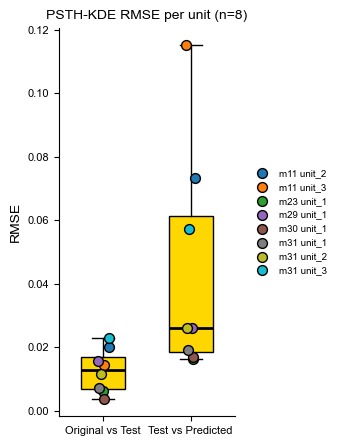

In [7]:
labels = ['Original vs Test', 'Test vs Predicted']
data   = [df_rmse['rmse_orig_test'].values, df_rmse['rmse_test_pred'].values]

fig, ax = plt.subplots(figsize=(3.5, 4.5))

bp = ax.boxplot(data, labels=labels, widths=0.5, patch_artist=True,
                showfliers=False,
                boxprops=dict(facecolor='gold', edgecolor='black'),
                medianprops=dict(color='black', linewidth=2),
                whiskerprops=dict(color='black'),
                capprops=dict(color='black'))

# one color per unit
unit_colors = plt.get_cmap('tab10')(np.linspace(0, 1, len(df_rmse)))

x_positions = np.array([1, 2])
for idx, (_, row) in enumerate(df_rmse.iterrows()):
    y     = np.array([row['rmse_orig_test'], row['rmse_test_pred']])
    x_jit = x_positions + rng.normal(0, 0.04, size=2)
    color = unit_colors[idx]
    ax.scatter(x_jit, y,
               s=50, edgecolor='black', facecolor=color, zorder=3,
               label=f'{row["moth"]} {row["unit"]}')

ax.set_ylabel('RMSE', fontsize=10)
ax.set_title(f'PSTH-KDE RMSE per unit (n={len(df_rmse)})', fontsize=10)
ax.tick_params(labelsize=8)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# legend outside on the right
ax.legend(loc='center left', bbox_to_anchor=(1.05, 0.5), fontsize=7, frameon=False)

plt.tight_layout()
fig.savefig(out_fig + 'BoxPlot_RMSE_OrigTest_vs_TestPred.pdf', bbox_inches='tight')
plt.show()

In [8]:
records_fr = []

for name, unit_name in moth_unit:
    pred_file = pred_path + name + '_' + unit_name + '_Prediction.pickle'
    with open(pred_file, 'rb') as f:
        saved = pickle.load(f)
    test_psth = saved[3]
    pred_psth = saved[5]
    
    mean_test = float(np.mean(test_psth))
    mean_pred = float(np.mean(pred_psth))
    
    records_fr.append({
        'moth':      name,
        'unit':      unit_name,
        'mean_test': mean_test,
        'mean_pred': mean_pred,
    })
    print(f'{name} {unit_name}: test={mean_test:.2f} Hz, pred={mean_pred:.2f} Hz')

df_fr = pd.DataFrame(records_fr).sort_values(['moth','unit']).reset_index(drop=True)
df_fr.to_csv(out_data + 'mean_firing_rates.csv', index=False)
df_fr

m23 unit_1: test=33.68 Hz, pred=35.04 Hz
m29 unit_1: test=5.92 Hz, pred=6.24 Hz
m30 unit_1: test=35.94 Hz, pred=34.05 Hz
m31 unit_1: test=21.42 Hz, pred=22.28 Hz
m31 unit_2: test=7.66 Hz, pred=7.80 Hz
m31 unit_3: test=3.08 Hz, pred=3.08 Hz
m11 unit_2: test=1.52 Hz, pred=1.41 Hz
m11 unit_3: test=0.92 Hz, pred=0.84 Hz


,moth,unit,mean_test,mean_pred
0,m11,unit_2,1.52,1.408
1,m11,unit_3,0.92,0.844
2,m23,unit_1,33.68,35.036
3,m29,unit_1,5.92,6.236
4,m30,unit_1,35.94,34.052
5,m31,unit_1,21.42,22.276
6,m31,unit_2,7.66,7.800
7,m31,unit_3,3.08,3.076


/var/folders/__/mwz7g0652137ypy1vqmvdp3c0000gn/T/ipykernel_5269/3545419737.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=labels, widths=0.5, patch_artist=True,


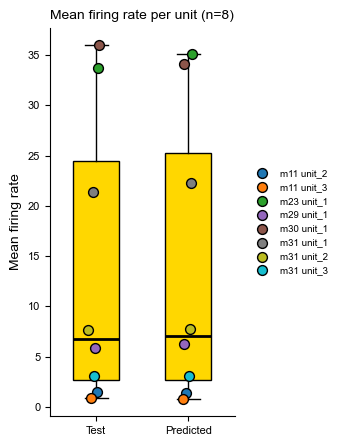

In [11]:
labels = ['Test', 'Predicted']
data   = [df_fr['mean_test'].values, df_fr['mean_pred'].values]

fig, ax = plt.subplots(figsize=(3.5, 4.5))

bp = ax.boxplot(data, labels=labels, widths=0.5, patch_artist=True,
                showfliers=False,
                boxprops=dict(facecolor='gold', edgecolor='black'),
                medianprops=dict(color='black', linewidth=2),
                whiskerprops=dict(color='black'),
                capprops=dict(color='black'))

unit_colors = plt.get_cmap('tab10')(np.linspace(0, 1, len(df_fr)))

x_positions = np.array([1, 2])
for idx, (_, row) in enumerate(df_fr.iterrows()):
    y     = np.array([row['mean_test'], row['mean_pred']])
    x_jit = x_positions + rng.normal(0, 0.04, size=2)
    color = unit_colors[idx]
    ax.scatter(x_jit, y,
               s=50, edgecolor='black', facecolor=color, zorder=3,
               label=f'{row["moth"]} {row["unit"]}')

ax.set_ylabel('Mean firing rate', fontsize=10)
ax.set_title(f'Mean firing rate per unit (n={len(df_fr)})', fontsize=10)
ax.tick_params(labelsize=8)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.legend(loc='center left', bbox_to_anchor=(1.05, 0.5), fontsize=7, frameon=False)

plt.tight_layout()
fig.savefig(out_fig + 'BoxPlot_MeanRate_TestVsPred.pdf', bbox_inches='tight')
plt.show()